# Collective spin flips for guided GFMC

The goal is to improve exploration of competing valleys without changing the LTFIM Hamiltonian. We develop a finite-imaginary-time proposal that can flip several spins at once, derive its importance weight, and check a local prototype against an independently constructed propagator.

**Status:** algorithm design and executable small-system validation. Valley trapping is a hypothesis to test; these checks do not establish that collective proposals improve the difficult Kagome results. This notebook executes bounded local calculations. It submits no remote jobs.

The scientific target remains the disorder-averaged connected-overlap length $R=\xi_R/L$ at fixed $h=0.15$, over accessible sizes through $L=10$.

## 1. What could be trapping the current projector?

Our convention is
$$H=V-\Gamma\sum_iX_i,\qquad V(s)=\sum_{\langle ij\rangle}K_{ij}s_is_j-h\sum_i s_i,\quad K_{ij}>0,\quad \Gamma>0,\quad s_i\in\{-1,+1\}.$$ Bounded positive guiding amplitudes are not required, but every guide value and ratio used numerically must be finite and strictly positive.

The current implementation in `../code/transformer_qmc/projector.py` draws exact exponential holding times and single-spin events with rates
$$r_i(s)=\Gamma\frac{\psi_T(s^{(i)})}{\psi_T(s)}.$$
It already allows multiple successive flips during each branching interval. Single-spin connectivity does not make a valley mathematically inaccessible. At finite walker population, however, rare connecting paths can be lost through unfavorable weights and repeated resampling. Poor guide ratios, population bias, short projection, and descendant collapse are competing explanations for inaccurate spectra.

Adding arbitrary positive multi-spin rates to this continuous-time generator would change the projected Hamiltonian unless an exact correction were supplied. Instead, we construct proposals for a finite-time propagator that already contains multi-spin transitions.

## 2. Derive the collective transition from the original Hamiltonian

Use the symmetric split operator
$$G_\delta=e^{-\delta V/2}e^{+\delta\Gamma\sum_iX_i}e^{-\delta V/2}.$$
Its local operator error is $O(\delta^3)$; at fixed total projection time its accumulated error is $O(\delta^2)$ for this finite system. The ground state of the split transfer matrix can differ from the true ground state at finite $\delta$, so this is a new time-step approximation relative to the current continuous-time event propagation. A convergence study is required.

All $X_i$ commute with each other. If $s'$ differs from $s$ on a subset $F$ of $x$ distinct sites,
$$G_\delta(s',s)=e^{-\delta[V(s')+V(s)]/2}\,[\sinh(a)]^x[\cosh(a)]^{N-x},\qquad a=\Gamma\delta.$$
These matrix elements are positive. Multiple flips are contributions of the physical finite-time propagation, not added terms $\prod_{i\in F}X_i$ in $H$. The split operator approximates the effect of intermediate diagonal energies; it does not reproduce their exact contribution at finite $\delta$.

A useful identity is
$$[\sinh(a)]^x[\cosh(a)]^{N-x}=e^{Na}p^x(1-p)^{N-x},\qquad p=\frac{1-e^{-2a}}2.$$
Thus the transverse factor alone can be sampled by independently flipping each site with probability $p$. The resulting flip count is binomial. Large collective rearrangements are naturally rare when $a$ is small.

## 3. Choose the number of flipped spins and correct the proposal

Draw $x\in\{0,\ldots,N\}$ from $q_x$, then choose one of the $\binom Nx$ subsets uniformly. This gives
$$Q(s'\mid s)=\frac{q_x}{\binom Nx}.$$
For an incoming guided density $f(s)=\psi_T(s)\Psi(s)$, the importance-sampled kernel is
$$\widetilde G_\delta(s',s)=\frac{\psi_T(s')}{\psi_T(s)}G_\delta(s',s).$$
The proposed child receives incremental weight
$$w(s\to s')=\frac{\widetilde G_\delta(s',s)}{Q(s'\mid s)}.$$
Consequently, for any test observable $A$,
$$\mathbb E_Q[wA(s')\mid s]=\sum_{s'}\widetilde G_\delta(s',s)A(s').$$
This identity holds before population normalization/resampling. It does not remove finite-population bias from repeated resampling or make normalized ratio estimates exactly unbiased. A reference-energy factor $e^{\delta E_T}$ is common to every walker in a step and cancels in normalized resampling; it must be retained if absolute growth normalization is measured.

We compare the natural binomial $b_x$ with a deliberately broader mixture
$$q_x=(1-\epsilon)b_x+\epsilon u_x,\qquad u_0=0,\quad u_x=1/N\;(1\leq x\leq N),\quad 0\leq\epsilon<1.$$
The binomial component preserves support for **every** subset, including no flip. Uniformly broad proposals are a diagnostic baseline, not an efficiency recommendation. Choosing exactly one fixed nonzero $x$ would omit nonzero kernel elements and give the wrong projection. Increasing $\delta$ to make large moves common also increases the time-step error.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.special import gammaln, logsumexp
from scipy.stats import binom

root = Path.cwd().resolve()
if not (root / 'code/transformer_qmc/projector.py').exists():
    root = root.parent
assert (root / 'code/transformer_qmc/projector.py').exists()
sys.path.insert(0, str(root / 'code'))
from transformer_qmc.physics import diagonal
from types import SimpleNamespace

rng = np.random.default_rng(20261102)

def count_distribution(n, gamma, delta, epsilon=0.0):
    assert n >= 1 and gamma > 0 and delta > 0 and 0 <= epsilon < 1
    p = -np.expm1(-2 * gamma * delta) / 2
    natural = binom.pmf(np.arange(n + 1), n, p)
    broad = np.r_[0.0, np.full(n, 1.0 / n)]
    q = (1 - epsilon) * natural + epsilon * broad
    q /= q.sum()
    if not np.all(q > 0):
        raise FloatingPointError('Proposal support underflow: use log probabilities for these parameters.')
    return q

def propose_subsets(states, gamma, delta, epsilon, rng):
    states = np.asarray(states, dtype=np.int8)
    walkers, n = states.shape
    q = count_distribution(n, gamma, delta, epsilon)
    counts = rng.choice(n + 1, size=walkers, p=q)
    proposed = states.copy()
    for row, x in enumerate(counts):
        sites = rng.choice(n, size=int(x), replace=False)
        proposed[row, sites] *= -1
    log_choose = gammaln(n + 1) - gammaln(counts + 1) - gammaln(n - counts + 1)
    log_q = np.log(q[counts]) - log_choose
    return proposed, counts, log_q

def log_increment(ham, gamma, delta, states, proposed, counts, log_q, log_guide):
    n = states.shape[1]
    a = gamma * delta
    log_kinetic = counts * np.log(np.sinh(a)) + (n - counts) * np.log(np.cosh(a))
    return (-delta * (diagonal(ham, states) + diagonal(ham, proposed)) / 2
            + log_kinetic + log_guide(proposed) - log_guide(states) - log_q)

def collective_step(ham, gamma, delta, states, log_guide, rng, epsilon=0.0):
    '''One prototype split-propagator step, with systematic population resampling.'''
    proposed, counts, log_q = propose_subsets(states, gamma, delta, epsilon, rng)
    log_w = log_increment(ham, gamma, delta, states, proposed, counts, log_q, log_guide)
    if not np.isfinite(log_w).all():
        raise FloatingPointError('Nonfinite incremental weight')
    weights = np.exp(log_w - logsumexp(log_w))
    m = len(states)
    positions = (rng.random() + np.arange(m)) / m
    cumulative = np.cumsum(weights)
    cumulative[-1] = 1.0
    parents = np.searchsorted(cumulative, positions)
    diagnostics = dict(ess=float(1 / (weights @ weights)),
                       log_mean_weight=float(logsumexp(log_w) - np.log(m)),
                       proposed_counts=counts, surviving_counts=counts[parents])
    return proposed[parents], parents, diagnostics

print('Prototype loaded. Proposal and weighting require no basis enumeration.')

Prototype loaded. Proposal and weighting require no basis enumeration.


## 4. Independent check on a frustrated triangle

Enumerate eight states **only for this validation**. Compare the analytic split kernel to dense matrix exponentials, verify the guide transformation and proposal correction for every source/destination pair, and compare split-operator ground states to the exact Hamiltonian. This checks the target of the prototype; it is not a Kagome accuracy benchmark.

In [2]:
n = 3
bits = (np.arange(2**n)[:, None] >> np.arange(n)) & 1
states = (1 - 2 * bits).astype(np.int8)
ham = SimpleNamespace(n_sites=n, bonds=np.array([[0, 1], [1, 2], [0, 2]]),
                      J=np.array([-0.7, -1.0, -0.9]), h=0.15)
gamma = 0.5
v = diagonal(ham, states)
transverse = np.zeros((2**n, 2**n))
for source in range(2**n):
    for site in range(n):
        transverse[source ^ (1 << site), source] = gamma
hamiltonian = np.diag(v) - transverse
energies, eigenvectors = np.linalg.eigh(hamiltonian)
psi_exact = np.abs(eigenvectors[:, 0])

# A simple evaluable positive guide, not an exact-label fit.
log_guide = lambda s: -0.2 * diagonal(ham, s)
guide = np.exp(log_guide(states))
delta = 0.2
x = np.count_nonzero(states[:, None, :] != states[None, :, :], axis=2)
a = gamma * delta
analytic = (np.exp(-delta * (v[:, None] + v[None, :]) / 2)
            * np.sinh(a)**x * np.cosh(a)**(n - x))
half = np.diag(np.exp(-delta * v / 2))
matrix_split = half @ expm(delta * transverse) @ half
np.testing.assert_allclose(analytic, matrix_split, rtol=1e-13, atol=1e-14)
guided = analytic * guide[:, None] / guide[None, :]

for epsilon in [0.0, 0.2, 0.6]:
    q = count_distribution(n, gamma, delta, epsilon)
    choose = np.exp(gammaln(n + 1) - gammaln(x + 1) - gammaln(n - x + 1))
    proposal = q[x] / choose
    np.testing.assert_allclose(proposal.sum(axis=0), 1, atol=1e-14)
    for source in range(2**n):
        incoming = np.repeat(states[source:source+1], 2**n, axis=0)
        log_w = log_increment(ham, gamma, delta, incoming, states, x[:, source],
                              np.log(proposal[:, source]), log_guide)
        np.testing.assert_allclose(proposal[:, source] * np.exp(log_w),
                                   guided[:, source], rtol=1e-13, atol=1e-14)
print('PASS: dense split kernel, proposal normalization, and all weighted kernel elements.')

# Exercise the actual random proposal and resampling; ESS is a single-step diagnostic.
population = np.tile(states, (256, 1))
children, parents, diagnostics = collective_step(ham, gamma, delta, population,
                                               log_guide, rng, epsilon=0.2)
assert children.shape == population.shape and np.isin(children, [-1, 1]).all()
assert np.all((parents >= 0) & (parents < len(population)))
print(f'Prototype step: {len(population)} walkers, weight ESS {diagnostics["ess"]:.1f}, '
      f'{len(np.unique(parents))} surviving parent indices.')

PASS: dense split kernel, proposal normalization, and all weighted kernel elements.
Prototype step: 2048 walkers, weight ESS 1637.8, 1596 surviving parent indices.


In [3]:
deltas = np.array([0.4, 0.2, 0.1, 0.05, 0.025])
errors = []
print('delta    ||p_split - p_ground||_1    effective ground energy error')
for step in deltas:
    half = np.diag(np.exp(-step * v / 2))
    kernel = half @ expm(step * transverse) @ half
    values, vectors = np.linalg.eigh(kernel)
    psi_split = np.abs(vectors[:, -1])
    error = np.sum(np.abs(psi_split**2 - psi_exact**2))
    energy_error = abs(-np.log(values[-1]) / step - energies[0])
    errors.append(error)
    print(f'{step:6.3f}    {error:24.7g}    {energy_error:28.7g}')
assert errors[-1] < errors[0] / 50
print('Observed successive probability-error ratios:', np.round(np.array(errors[:-1]) / errors[1:], 3))
print('These are deterministic triangle checks, not finite-population GFMC error estimates.')

delta    ||p_split - p_ground||_1    effective ground energy error
 0.400                   0.0204082                      0.02440804
 0.200                 0.005433115                     0.006452579
 0.100                  0.00138117                     0.001636679
 0.050                0.0003467612                    0.0004106679
 0.025                8.678269e-05                     0.000102761
Observed successive probability-error ratios: [3.756 3.934 3.983 3.996]
These are deterministic triangle checks, not finite-population GFMC error estimates.


## 5. More large proposals can mean fewer useful walkers

To isolate the kinetic proposal correction, temporarily set $V=0$ and $\psi_T=1$. The normalized target count distribution is the binomial $b_x$. The importance factor is $b_x/q_x$, with mean one. Its second moment gives the large-population single-step effective sample fraction
$$\frac{\mathrm{ESS}}M\longrightarrow\left[\sum_x\frac{b_x^2}{q_x}\right]^{-1}.$$
A broad proposal creates more large flips, but their total physical weight remains small. The figure below is an analytic kinetic-only illustration at $N=48$ ($L=4$), not a simulation of the frustrated model. Diagonal energies and the guide can make weight fluctuations much better or worse.

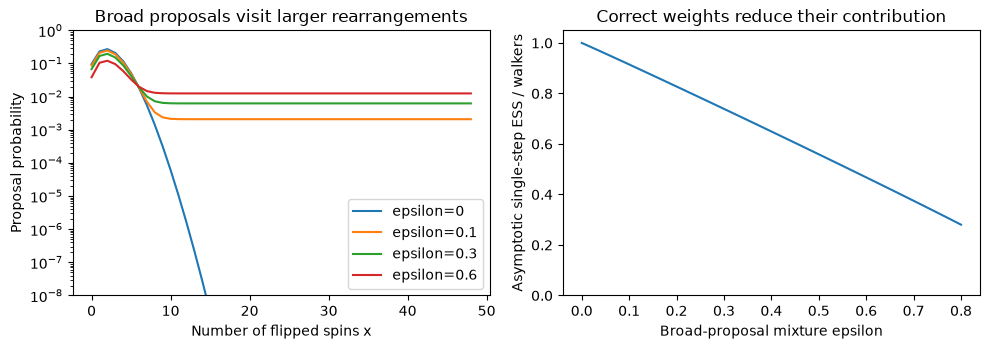

In [4]:
n_demo, gamma_demo, delta_demo = 48, 0.5, 0.1
counts = np.arange(n_demo + 1)
b = count_distribution(n_demo, gamma_demo, delta_demo, epsilon=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for epsilon in [0, 0.1, 0.3, 0.6]:
    q = count_distribution(n_demo, gamma_demo, delta_demo, epsilon)
    axes[0].semilogy(counts, q, label=f'epsilon={epsilon:g}')
axes[0].set(xlabel='Number of flipped spins x', ylabel='Proposal probability',
            ylim=(1e-8, 1), title='Broad proposals visit larger rearrangements')
axes[0].legend()
epsilons = np.linspace(0, 0.8, 81)
fractions = []
for epsilon in epsilons:
    q = count_distribution(n_demo, gamma_demo, delta_demo, epsilon)
    fractions.append(1 / np.sum(b * b / q))
axes[1].plot(epsilons, fractions)
axes[1].set(xlabel='Broad-proposal mixture epsilon', ylabel='Asymptotic single-step ESS / walkers',
            ylim=(0, 1.05), title='Correct weights reduce their contribution')
fig.tight_layout()
plt.show()

## 6. Improve the proposal using the frustrated Hamiltonian

Uniform random subsets establish the weighting logic. A useful proposal should also favor changes with modest $\Delta V$ and reasonable guide ratios. For a flipped set $F$, only bonds crossing its boundary change their interaction energy:
$$\Delta V=-2\sum_{\langle ij\rangle:\,i\in F,\,j\notin F}K_{ij}s_is_j+2h\sum_{i\in F}s_i,$$
where each undirected boundary bond is included once. Connected clusters and alternating loops are candidates because their boundary or frustration pattern can be more favorable than that of unrelated random sites. Random bonds and nonzero $h$ remove any generic zero-cost guarantee.

For a state-dependent subset proposal $Q(F\mid s)$, replace the uniform-subset probability above with its actual probability. If several growth histories yield the same set, the endpoint probability is the sum over those histories. Using the probability of just one history as though it were the endpoint probability gives incorrect weights unless an explicitly derived auxiliary-variable construction accounts for the histories. A practical first cluster prototype could use a finite, deterministically generated library of distinct subsets and a known categorical distribution, mixed with the full-support binomial proposal.

A Metropolis test based only on $\Delta V$ samples a classical energy distribution, and a test based only on $\psi_T^2$ preserves the variational guide distribution. Neither automatically preserves the projected guided density $\psi_T\Psi$. Any rejuvenation step inserted between GFMC steps needs a proof for its intended target.

## 7. The benchmark that decides whether this helps

Start with the four existing exact-validation contexts, all at $L=2$, $N=12$, and $h=0.15$:

| Gamma | Disorder | Role |
|---:|---:|---|
| 0.25 | 50025 | Difficult low-field spectrum |
| 0.25 | 50059 | Another difficult low-field realization |
| 0.50 | 50043 | Small-gap realization |
| 0.75 | 50004 | Better-behaved comparison |

Compare four methods using the **same frozen guide** and initialization ensemble: the existing continuous-time single-event GFMC; the split propagator with its natural binomial proposal; the guide-aware sequential proposal below; and the same split propagator with a small broad-proposal mixture. Keeping the two split methods at the same time step isolates proposal changes from propagator changes. The implemented L=2 controlled comparison uses cached frozen original and corrected guides. The low-order correction was fitted using enumeration and is a small-system diagnostic. A separate GPU cost probe uses the scalable frozen neural guide directly, without enumeration. Exact eigenvectors must not tune the production proposal.

Use a short sequence such as $\delta=0.1,0.05,0.025$ as starting trial settings, not accepted tolerances. Compare at equal **total imaginary projection time**, and count guide evaluations, measured CPU time, and memory. Repeat with more walkers and longer projection and forward times. Fixed step count across different $\delta$ would change projection time. If resampling occurs every step, changing $\delta$ also changes the resampling cadence: isolate that effect with a cadence audit or acknowledge it in the population convergence checks.

Record all runs, including failed or collapsed populations:

- Bias and uncertainty in each connected-overlap spectrum, followed by $\xi_R/L$; energy alone is insufficient.
- Proposed and surviving flip counts, weight ESS, distinct ancestors, largest lineage, and descendant ESS at each forward time. Many proposed large moves with no surviving descendants do not demonstrate improved exploration.
- Overlap with several fixed reference configurations, initial-state dependence, and transitions between prespecified overlap regions. A region change is only a diagnostic proxy for valley transport.
- Independent-run reproducibility, early/late consistency, and sensitivity to population, projection time, forward time, and split time step.

Endpoint walkers sample a **mixed guided density**, not $|\Psi_0|^2$. Reuse the descendant ancestry map returned by `collective_step` to construct forward-walking pure moment estimates. Keep four independent populations for the existing disjoint-replica connected estimator. The prototype step alone is not a complete pure-estimator production solver. Average spectra over quenched disorders before reducing to $\xi_R/L$; these four selected contexts are a method benchmark, not a representative disorder average.

Advance to $L=4$ only if the collective proposal reduces spectral error at comparable measured cost, with controlled time-step effects and viable ancestry. Ground-state projection has no thermal beta convergence requirement; it needs projection-time, population, and estimator convergence. Success at $L=2$ does not establish equilibration through $L=10$.

## 8. Implemented guide-aware proposal

The production kernel in `collective_projector.py` visits every site once in fixed order. Let $u$ be the intermediate state just before visiting site $i$, and $u^{(i)}$ its single-flip neighbor. Set
$$a_i(u)=\tanh(\Gamma\delta)\frac{\psi_T(u^{(i)})}{\psi_T(u)},\qquad p_i(u)=\frac{a_i(u)}{1+a_i(u)}.$$
The product of Bernoulli probabilities gives $Q_g(s'\mid s)$. Each endpoint has one history because each site is visited exactly once. The target weight is still the full split kernel divided by this proposal. The site order affects variance but not the weighted target.

For the broad branch, draw a count uniformly from $1,\ldots,N$, then a uniform subset of that size. With $Q_b=1/[N\binom Nx]$ for $x>0$, use
$$Q(s'\mid s)=(1-\epsilon)Q_g(s'\mid s)+\epsilon Q_b(s'\mid s)$$
in the denominator for **every** sampled endpoint. The implemented broad mixture uses $\epsilon=0.1$. The natural proposal uses independent flip probability $\tanh(\Gamma\delta)/[1+\tanh(\Gamma\delta)]$.

Four populations resample independently. Descendant counts weight the tagged magnetization and pair moments; disjoint replica products estimate the connected spectrum. Checkpoints store the RNG, walker states, tags, ancestor maps, and accumulated moments. Interrupted and uninterrupted forward walks agree bit for bit for all four methods.

Exact evaluation references include continuous-time and split ground states, and their finite-equilibration/forward-walking targets. For a guide start, the initial physical amplitude is $\psi_T$; a uniform walker start corresponds to $1/\psi_T$. These references separate splitting, finite projection, and population/sampling error. They never enter the proposals.

## 9. AutoDL benchmark snapshot

The cells below read preserved local snapshots. The initial timing pilot has one short run per setting, so its errors do not establish a performance ranking. The repeated main benchmark has eight runs per setting; population, time, and initialization audits have four. Every ancestry alarm and invalid length ratio is retained.

The remote CPU campaign runs up to 18 workers. A separate H800 probe measures direct guide cost at $L=2,4,6,8,10$, using short trajectories only. Higher weight ESS can require substantially more guide evaluations; both accuracy and cost matter.

In [5]:
import json
from transformer_qmc.collective_campaign import assess
snapshot = root / 'data/kagome/ltfim_collective_gfmc_v1'
report = assess(snapshot / 'pilot')
print('Validated pilot runs:', report['completed'])
print('Corrected guide, short pilot: maximum relative spectral error')
for row in report['rows']:
    if row['guide'] == 'corrected' and row['method'] in ('ct', 'guided', 'broad') and row['delta'] in (.1, .05):
        print(f"Gamma={row['gamma']:4.2f} s={row['sample_id']} {row['method']:7s} delta={row['delta']:.2f}: "
              f"{100*row['max_relative_bias']:7.2f}%  alarms={row['alarms']}")
print('One repeat per setting: descriptive pilot only.')

Validated pilot runs: 56
Corrected guide, short pilot: maximum relative spectral error
Gamma=0.25 s=50025 broad   delta=0.05:   73.61%  alarms=0
Gamma=0.25 s=50025 broad   delta=0.10:   82.01%  alarms=0
Gamma=0.25 s=50025 ct      delta=0.10:   83.97%  alarms=0
Gamma=0.25 s=50025 guided  delta=0.05:   84.57%  alarms=0
Gamma=0.25 s=50025 guided  delta=0.10:   84.33%  alarms=0
Gamma=0.25 s=50059 broad   delta=0.05:  161.64%  alarms=0
Gamma=0.25 s=50059 broad   delta=0.10:  142.50%  alarms=0
Gamma=0.25 s=50059 ct      delta=0.10:  153.87%  alarms=0
Gamma=0.25 s=50059 guided  delta=0.05:  150.70%  alarms=0
Gamma=0.25 s=50059 guided  delta=0.10:  154.25%  alarms=0
Gamma=0.50 s=50043 broad   delta=0.05:   23.84%  alarms=0
Gamma=0.50 s=50043 broad   delta=0.10:   18.42%  alarms=0
Gamma=0.50 s=50043 ct      delta=0.10:   20.55%  alarms=0
Gamma=0.50 s=50043 guided  delta=0.05:   21.25%  alarms=0
Gamma=0.50 s=50043 guided  delta=0.10:   10.53%  alarms=0
Gamma=0.75 s=50004 broad   delta=0.05:   19

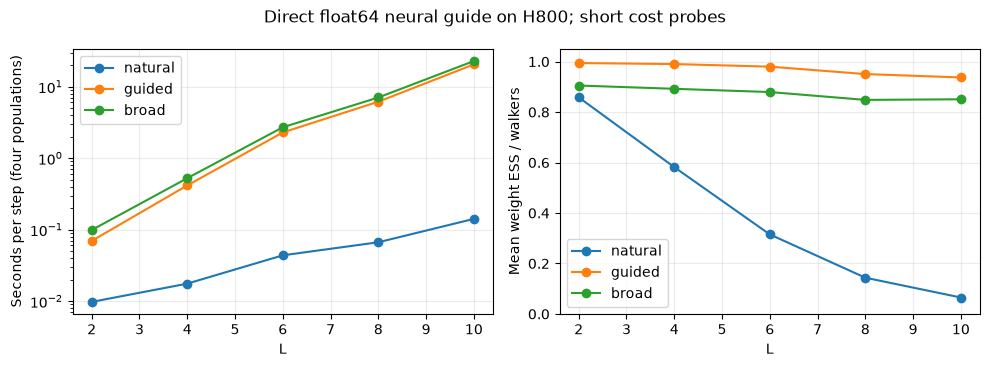

GPU snapshot: stopped_time_cap completed settings: 41
Repeated benchmark snapshot: {'state': 'completed', 'completed_runs': 984, 'updated_unix': 1793639110.215757}


In [6]:
gpu = json.loads((snapshot / 'gpu/results.json').read_text())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for method in ('natural', 'guided', 'broad'):
    rows = [r for r in gpu['rows'] if r['walkers'] == 128 and r['method'] == method]
    if rows:
        axes[0].plot([r['L'] for r in rows], [r['median_step_seconds'] for r in rows], 'o-', label=method)
        axes[1].plot([r['L'] for r in rows], [r['mean_weight_ess']/r['walkers'] for r in rows], 'o-', label=method)
axes[0].set(xlabel='L', ylabel='Seconds per step (four populations)', yscale='log')
axes[1].set(xlabel='L', ylabel='Mean weight ESS / walkers', ylim=(0, 1.05))
for ax in axes: ax.legend(); ax.grid(alpha=.25)
fig.suptitle('Direct float64 neural guide on H800; short cost probes')
fig.tight_layout()
plt.show()
print('GPU snapshot:', gpu['state'], 'completed settings:', len(gpu['rows']))
status_path = snapshot / 'benchmark/status.json'
if status_path.exists(): print('Repeated benchmark snapshot:', json.loads(status_path.read_text()))

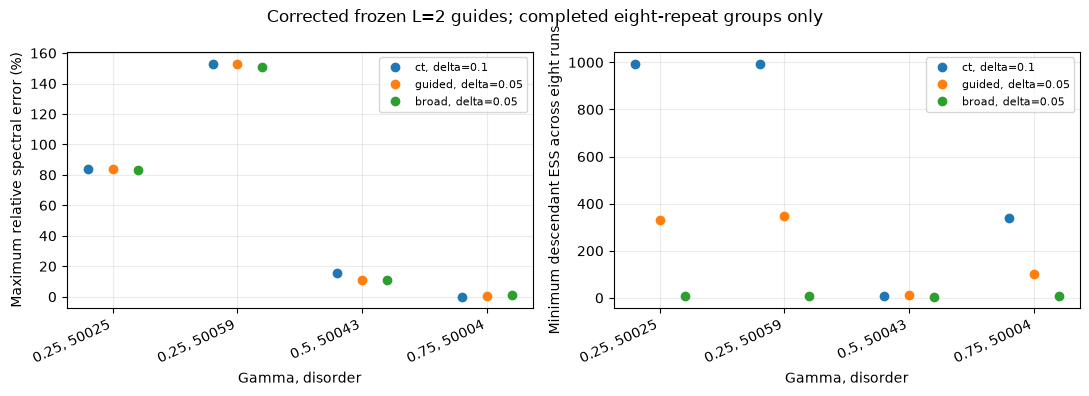

Validated benchmark snapshot: 984 runs
These are selected-disorder diagnostics; the figures do not qualify finite-size scaling.


In [7]:
benchmark = assess(snapshot / 'benchmark')
rows = [r for r in benchmark['rows'] if r['audit'] == 'main' and r['guide'] == 'corrected' and r['repeats'] == 8]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
contexts = [(0.25, 50025), (0.25, 50059), (0.5, 50043), (0.75, 50004)]
for method, delta, offset in [('ct', .1, -.2), ('guided', .05, 0), ('broad', .05, .2)]:
    subset = [r for r in rows if r['method'] == method and r['delta'] == delta]
    positions = [contexts.index((r['gamma'], r['sample_id'])) + offset for r in subset]
    axes[0].plot(positions, [100*r['max_relative_bias'] for r in subset], 'o', label=f'{method}, delta={delta}')
    axes[1].plot(positions, [r['minimum_descendant_ess'] for r in subset], 'o', label=f'{method}, delta={delta}')
labels = [f'{g}, {s}' for g, s in contexts]
for ax in axes:
    ax.set_xticks(range(4)); ax.set_xticklabels(labels, rotation=25, ha='right')
    ax.set_xlabel('Gamma, disorder'); ax.grid(alpha=.25); ax.legend(fontsize=8)
axes[0].set_ylabel('Maximum relative spectral error (%)')
axes[1].set_ylabel('Minimum descendant ESS across eight runs')
fig.suptitle('Corrected frozen L=2 guides; completed eight-repeat groups only')
fig.tight_layout()
figure_dir = root / 'figures/collective_gfmc'; figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / 'l2_spectral_error_and_ancestry.png', dpi=180, bbox_inches='tight')
fig.savefig(figure_dir / 'l2_spectral_error_and_ancestry.pdf', bbox_inches='tight')
plt.show()
print('Validated benchmark snapshot:', benchmark['completed'], 'runs')
print('These are selected-disorder diagnostics; the figures do not qualify finite-size scaling.')

## 10. Why a low-variance guide can still miss the ground state

Offline exact diagnostics reveal a concrete failure in the two $\Gamma=0.25$ corrected guides. Their squared ground-state overlaps are approximately $4.9\times10^{-10}$ and $4.2\times10^{-11}$. Their variational energy errors nearly equal the first excitation gaps, while their local-energy variances are only about $10^{-5}$. The original guides have much larger ground-state overlaps, around $0.008$.

A positive guide can approximate a metastable sector so closely that ordinary walker populations rarely represent the small amplitude needed to escape. The long forward-walking reference can then behave very differently from an affordable finite population. Small weight variance and healthy ancestry do not rule this out.

The follow-up mixes normalized probabilities,
$$\psi_{\rm mix}(s)=\sqrt{(1-a)\psi_{\rm corrected}(s)^2+a\psi_{\rm original}(s)^2},\qquad a\in\{0.01,0.1,0.5\}.$$
This recipe uses frozen guide probabilities and no exact-state labels. It is tested as an enumerated $L=2$ diagnostic. A scalable version would need both component amplitudes and their normalized sampling distributions. The CPU follow-up is queued after the primary benchmark and preserves its own inputs, source hashes, and results.

In [8]:
diagnosis = json.loads((snapshot / 'low_modes.json').read_text())
print('Offline exact diagnosis (evaluation only)')
for row in diagnosis['rows']:
    original = row['guides']['original']; corrected = row['guides']['corrected']
    print(f"Gamma={row['gamma']:.2f} s={row['sample_id']} gap={row['gaps'][1]:.8f} "
          f"corrected energy error={corrected['energy_error']:.8f} "
          f"variance={corrected['variance']:.3g} "
          f"ground probability={corrected['ground_probability']:.3g} "
          f"(original {original['ground_probability']:.3g})")

Offline exact diagnosis (evaluation only)
Gamma=0.25 s=50025 gap=0.07962844 corrected energy error=0.07962958 variance=1.11e-05 ground probability=4.9e-10 (original 0.00884)
Gamma=0.25 s=50059 gap=0.13623329 corrected energy error=0.13623437 variance=1.25e-05 ground probability=4.21e-11 (original 0.00791)
Gamma=0.50 s=50043 gap=0.02847779 corrected energy error=0.00091861 variance=0.00367 ground probability=0.982 (original 0.656)
Gamma=0.75 s=50004 gap=0.30592097 corrected energy error=0.00153095 variance=0.015 ground probability=1 (original 0.75)


## What this notebook establishes

The original finite-time transverse propagator permits collective flips with positive, calculable weights. An arbitrary full-support flip-count distribution can be corrected to the same split kernel; the executable triangle checks verify that correction and expose the finite-step approximation.

What remains open is whether a useful collective proposal can transport appreciable **weighted** population between the troublesome Kagome valleys at affordable cost. Broad random flips are a controlled first experiment. Structured proposals should follow only with computable proposal probabilities and evidence from the matched benchmark.

Related local sources: [current continuous-time propagator](../code/transformer_qmc/projector.py), [independent-replica pure estimator](../code/transformer_qmc/independent_replica_projector.py), and [accessible-size scientific goal](../code/transformer_qmc/FINITE_SIZE_GOAL.md).

## 11. Executed Hamiltonian-aware triangle update

Split the Kagome triangles into two vertex-disjoint layers. Put each bond in its
unique triangle and divide each on-site longitudinal/transverse field equally
between its two triangles. Then $H=A+B$ exactly. Use
$$G_\delta=e^{-\delta A/2}e^{-\delta B}e^{-\delta A/2}.$$
Each factor is an exact positive eight-state local exponential. For block $K$,
sample $q(y|x)=K_{yx}\psi_T(y)/Z(x)$ and multiply the weight by
$Z(x)/\psi_T(x)$. Intermediate guide ratios telescope; the correction is a
**path correction**, not an endpoint approximation. This gives second-order
projection with no arbitrary extra spin-flip term.

Tests verify the original full Hamiltonian, operator symmetry, cubic one-step
error, weighted path moments, cache/direct equivalence, lattice covers through
L=10, and checkpoint recovery. The pilot below has only two short repeats per
setting and uses frozen enumerated L2 guides. Its exact references are computed
for the actual triangle product, including the finite-projection schedule.


In [9]:
from transformer_qmc.triangle_campaign import assess as assess_triangle
triangle_folder=root/'data/kagome/ltfim_triangle_gfmc_v1/pilot'
triangle=assess_triangle(triangle_folder,snapshot/'benchmark/references.json')
print('Validated triangle-comparison pilot runs:',triangle['completed'])
for r in triangle['rows']:
    if r['guide']=='corrected' and r['delta']==.1:
        sampling=100*max(abs(np.asarray(r['relative_sampling_error'])))
        split=100*max(abs(np.asarray(r['split_ground_relative_bias'])))
        print(f"{r['gamma']:.2f} {r['sample_id']} {r['method']:8s}: ground error "
              f"{100*r['max_relative_bias']:.3f}%, finite-target sampling error {sampling:.3f}%, "
              f"split-ground error {split:.5f}%")


Validated triangle-comparison pilot runs: 80
0.25 50025 ct      : ground error 83.268%, finite-target sampling error 2.763%, split-ground error 0.00000%
0.25 50025 guided  : ground error 84.533%, finite-target sampling error 4.891%, split-ground error 0.01427%
0.25 50025 triangle: ground error 83.849%, finite-target sampling error 0.865%, split-ground error 0.00770%
0.25 50059 ct      : ground error 151.813%, finite-target sampling error 0.496%, split-ground error 0.00000%
0.25 50059 guided  : ground error 150.924%, finite-target sampling error 0.833%, split-ground error 0.00769%
0.25 50059 triangle: ground error 154.548%, finite-target sampling error 0.616%, split-ground error 0.00224%
0.50 50043 ct      : ground error 20.659%, finite-target sampling error 1.521%, split-ground error 0.00000%
0.50 50043 guided  : ground error 12.104%, finite-target sampling error 8.638%, split-ground error 1.55723%
0.50 50043 triangle: ground error 19.835%, finite-target sampling error 0.596%, split-gr

### What changed scientifically

The triangle rule passed correctness checks but did not rescue the two difficult
corrected low-field guides. At step 0.1 their errors remain about 84% and 155%.
The sampler is within roughly 1% of its exact finite-time target there: the bad
target is already explained by the initial guide and projection schedule.

This motivated testing guide representation itself. See the executed
[Jastrow/RBM comparison](simple_guiding_wavefunctions.ipynb). Its small-system
results separate metastable optimization failures from successful simple fits;
they do not qualify larger-system sampled training.
